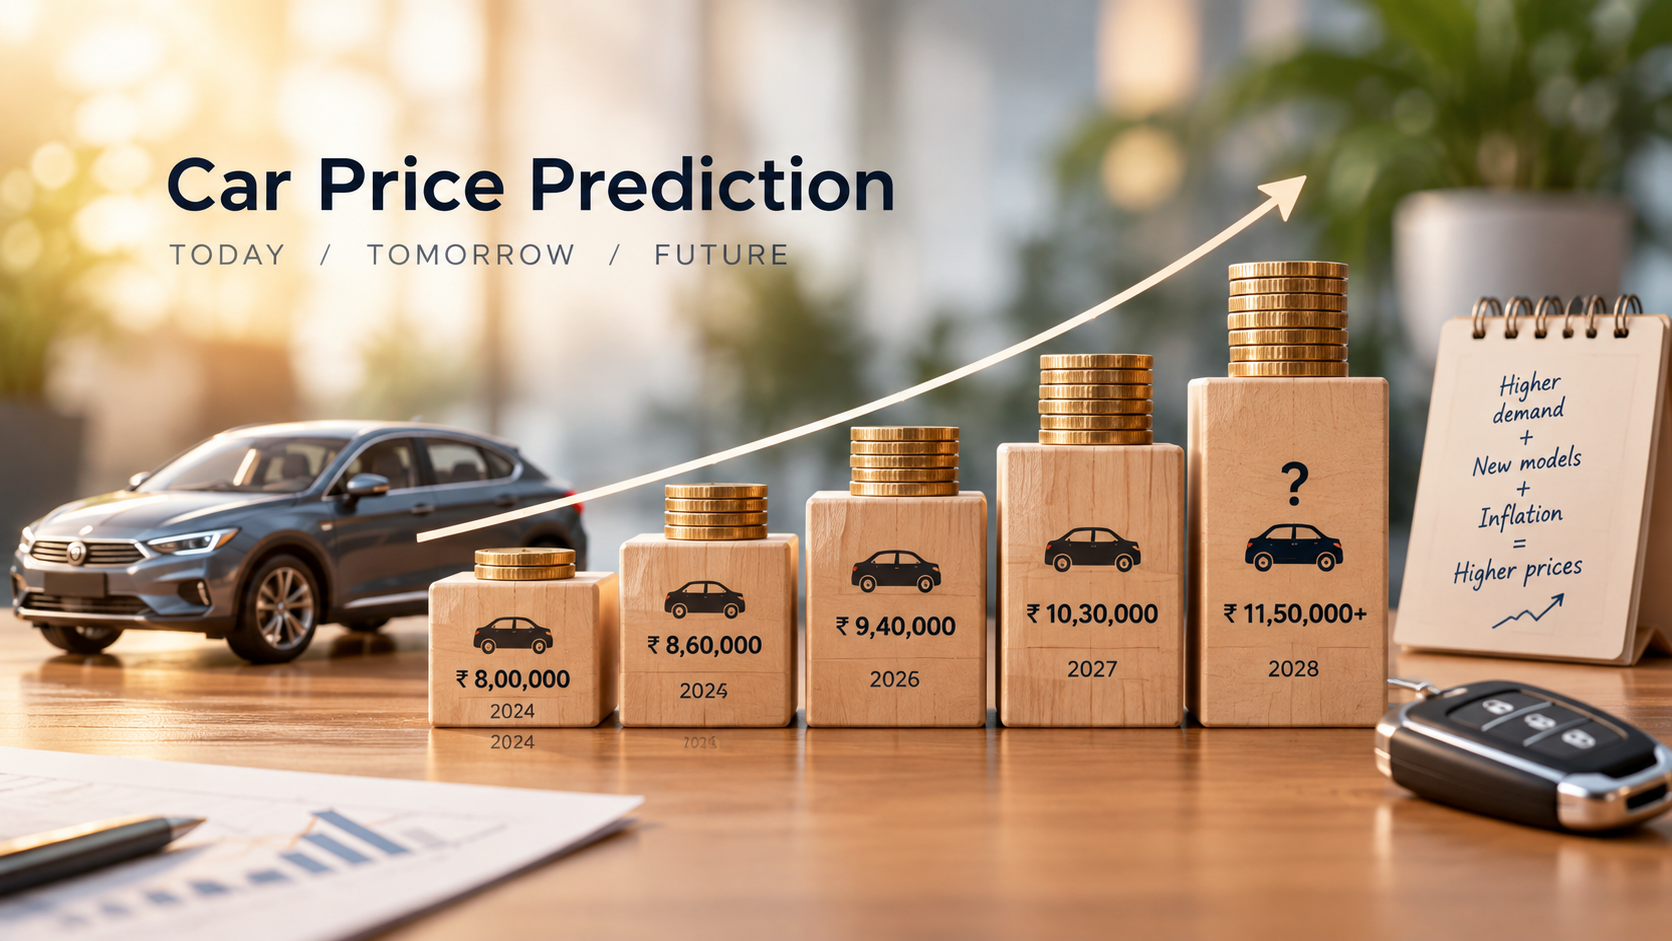

## 1. Business Understanding and Problem Statement

### Business Understanding

The automobile industry has a wide range of cars with different prices based on their features, brand, manufacturing year, fuel type, transmission, mileage, engine capacity, and kilometers driven. Predicting the correct price of a car is important for both buyers and sellers to make informed decisions.

The **Car Price Prediction** project uses Machine Learning techniques to estimate the selling price of a car based on its specifications and historical data. This system helps used-car buyers understand a vehicle's expected market value and enables sellers and dealerships to set competitive prices.

### Problem Statement

Determining the accurate price of a used car is challenging because its value depends on multiple factors, such as the car's age, brand, mileage, fuel type, transmission, and overall condition. Traditional pricing methods may lead to inaccurate estimates and inconsistent pricing.

The objective of this project is to develop a Machine Learning model that predicts the estimated selling price of a car based on its relevant features. The model will learn patterns from historical car data and use them to generate price predictions for new cars.

### Project Objectives

* Analyze historical car sales data to identify important factors affecting car prices.
* Perform data cleaning, preprocessing, and exploratory data analysis.
* Identify the relationship between car features and selling prices.
* Build and evaluate suitable Machine Learning regression models.
* Predict the estimated selling price of a car based on user-provided details.
* Help buyers, sellers, and dealerships make better pricing decisions.


In [111]:
import pandas as pd
import numpy as np

In [112]:
df = pd.read_csv("CarPricePrediction.csv")
df.head()


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [156]:
df.shape


(3198, 15)

In [157]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3198 entries, 0 to 4339
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   name                          3198 non-null   int64
 1   year                          3198 non-null   int64
 2   selling_price                 3198 non-null   int64
 3   km_driven                     3198 non-null   int64
 4   fuel_Diesel                   3198 non-null   int64
 5   fuel_Electric                 3198 non-null   int64
 6   fuel_LPG                      3198 non-null   int64
 7   fuel_Petrol                   3198 non-null   int64
 8   seller_type_Individual        3198 non-null   int64
 9   seller_type_Trustmark Dealer  3198 non-null   int64
 10  transmission_Manual           3198 non-null   int64
 11  owner_Fourth & Above Owner    3198 non-null   int64
 12  owner_Second Owner            3198 non-null   int64
 13  owner_Test Drive Car          3198 non

In [115]:
df.describe()

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [116]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner'],
      dtype='object')

## Data Preprocessing

In [117]:
df.duplicated().sum()


np.int64(763)

In [118]:
duplicates = df[df.duplicated(keep=False)].sort_values(
    by=['name', 'year', 'selling_price']
).head(20)
print(duplicates)

                                      name  year  selling_price  km_driven  \
3912        Ambassador CLASSIC 1500 DSL AC  2005         120000      50000   
4016        Ambassador CLASSIC 1500 DSL AC  2005         120000      50000   
99    Audi A4 2.0 TDI 177 Bhp Premium Plus  2013        1150000      53000   
2578  Audi A4 2.0 TDI 177 Bhp Premium Plus  2013        1150000      53000   
554                Audi A4 3.0 TDI Quattro  2013        1580000      86000   
573                Audi A4 3.0 TDI Quattro  2013        1580000      86000   
592                Audi A4 3.0 TDI Quattro  2013        1580000      86000   
611                Audi A4 3.0 TDI Quattro  2013        1580000      86000   
899                Audi A4 3.0 TDI Quattro  2013        1580000      86000   
918                Audi A4 3.0 TDI Quattro  2013        1580000      86000   
1077               Audi A4 3.0 TDI Quattro  2013        1580000      86000   
1835               Audi A4 3.0 TDI Quattro  2013        1580000 

In [119]:
df.drop_duplicates(inplace = True)

In [120]:
df.duplicated().sum()

np.int64(0)

In [121]:
df.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

In [122]:
df.shape

(3577, 8)

<Axes: ylabel='Density'>

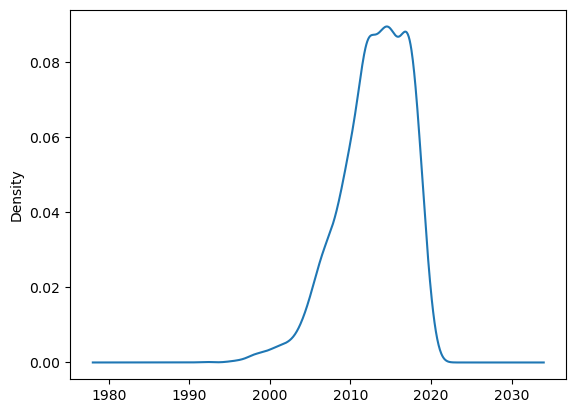

In [123]:
df['year'].plot(kind = 'kde')

<Axes: ylabel='Density'>

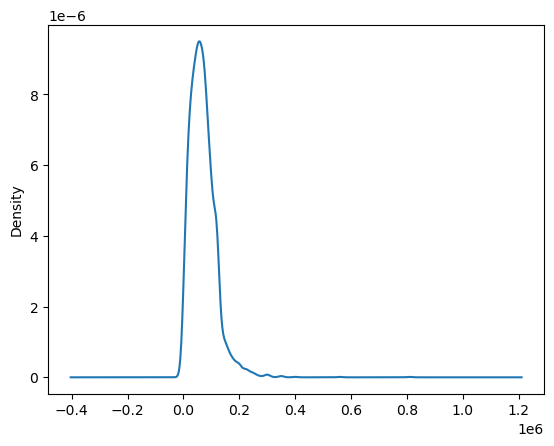

In [124]:
df['km_driven'].plot(kind = 'kde')

<Axes: ylabel='Density'>

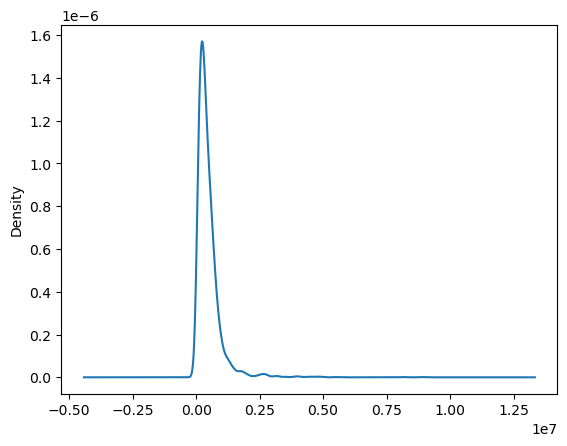

In [125]:
df['selling_price'].plot(kind = 'kde')

<Axes: >

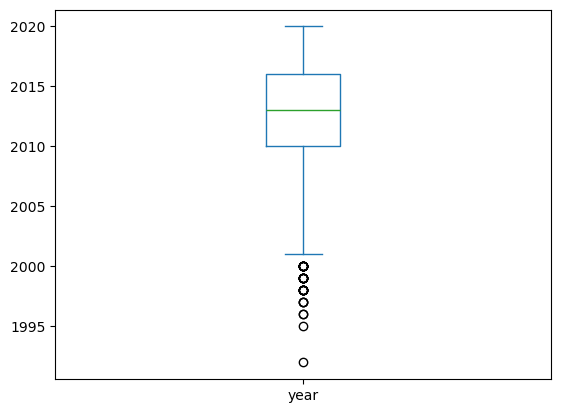

In [126]:
df['year'].plot(kind = 'box')

<Axes: >

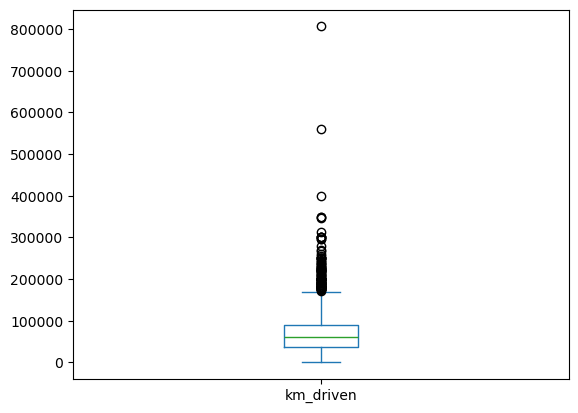

In [127]:
df['km_driven'].plot(kind = 'box')

<Axes: >

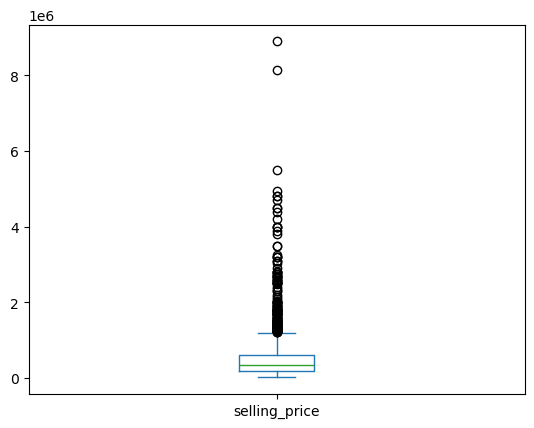

In [128]:
df['selling_price'].plot(kind = 'box')

In [129]:
Q1 = df['selling_price'].quantile(0.25)
Q3 = df['selling_price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

outliers = df[
    (df['selling_price'] < lower_bound) |
    (df['selling_price'] > upper_bound)
]

print("Outlier Count:", len(outliers))
print("Outlier Percentage:", (len(outliers) / len(df)) * 100)

   

Lower Bound: -400000.0
Upper Bound: 1200000.0
Outlier Count: 170
Outlier Percentage: 4.752585965893206


In [130]:
Q1 = df['year'].quantile(0.25)
Q3 = df['year'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

outliers = df[
    (df['year'] < lower_bound) |
    (df['year'] > upper_bound)
]

print("Outlier Count:", len(outliers))
print("Outlier Percentage:", (len(outliers) / len(df)) * 100)


Lower Bound: 2001.0
Upper Bound: 2025.0
Outlier Count: 37
Outlier Percentage: 1.034386357282639


In [131]:
Q1 = df['km_driven'].quantile(0.25)
Q3 = df['km_driven'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

outliers = df[
    (df['km_driven'] < lower_bound) |
    (df['km_driven'] > upper_bound)
]

print("Outlier Count:", len(outliers))
print("Outlier Percentage:", (len(outliers) / len(df)) * 100)


Lower Bound: -45000.0
Upper Bound: 171000.0
Outlier Count: 106
Outlier Percentage: 2.9633771316745876


selling_price: 0 outliers remaining
year: 0 outliers remaining
km_driven: 0 outliers remaining


<Axes: >

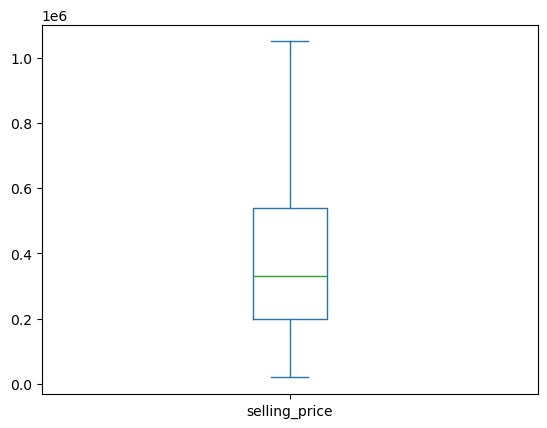

In [138]:
df['selling_price'].plot(kind = 'box')

<Axes: >

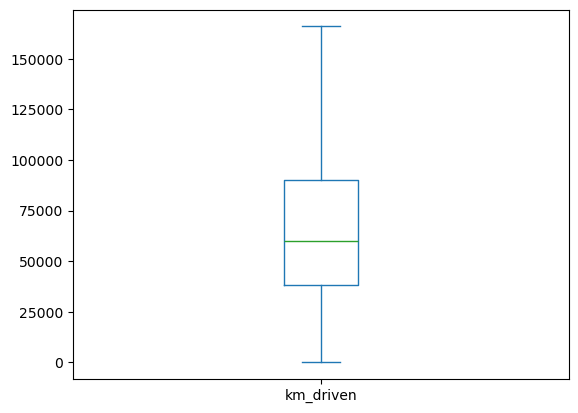

In [139]:
df['km_driven'].plot(kind = 'box')

<Axes: >

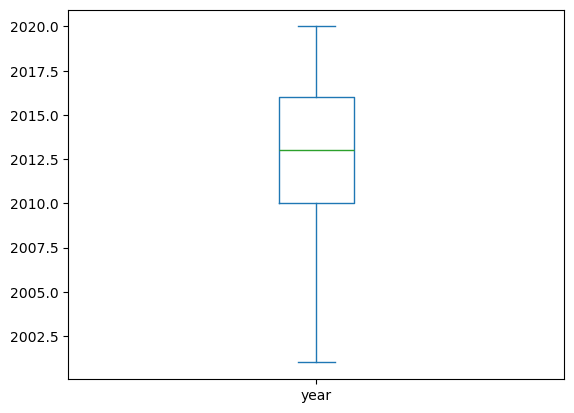

In [140]:
df['year'].plot(kind = 'box')

## Model Building

In [141]:
df = pd.get_dummies(
    df,
    columns=['fuel', 'seller_type', 'transmission', 'owner'],
    drop_first=True,
    dtype=int
)


In [142]:
df

,name,year,selling_price,km_driven,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,Maruti 800 AC,2007,60000,70000,0,0,0,1,1,0,1,0,0,0,0
1,Maruti Wagon R LXI Minor,2007,135000,50000,0,0,0,1,1,0,1,0,0,0,0
2,Hyundai Verna 1.6 SX,2012,600000,100000,1,0,0,0,1,0,1,0,0,0,0
3,Datsun RediGO T Option,2017,250000,46000,0,0,0,1,1,0,1,0,0,0,0
4,Honda Amaze VX i-DTEC,2014,450000,141000,1,0,0,0,1,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),2014,409999,80000,1,0,0,0,1,0,1,0,1,0,0
4336,Hyundai i20 Magna 1.4 CRDi,2014,409999,80000,1,0,0,0,1,0,1,0,1,0,0
4337,Maruti 800 AC BSIII,2009,110000,83000,0,0,0,1,1,0,1,0,1,0,0
4338,Hyundai Creta 1.6 CRDi SX Option,2016,865000,90000,1,0,0,0,1,0,1,0,0,0,0


In [143]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['name'] = le.fit_transform(df['name'])

In [144]:
df['name'].head()

0    664
1    921
2    444
3     83
4    231
Name: name, dtype: int64

In [145]:
X = df.drop(columns = ['selling_price'])
X.head()

,name,year,km_driven,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,664,2007,70000,0,0,0,1,1,0,1,0,0,0,0
1,921,2007,50000,0,0,0,1,1,0,1,0,0,0,0
2,444,2012,100000,1,0,0,0,1,0,1,0,0,0,0
3,83,2017,46000,0,0,0,1,1,0,1,0,0,0,0
4,231,2014,141000,1,0,0,0,1,0,1,0,1,0,0


In [146]:
Y = df['selling_price']
Y.head()

0     60000
1    135000
2    600000
3    250000
4    450000
Name: selling_price, dtype: int64

In [185]:
Y.max()

1050000

In [147]:
import sklearn
from sklearn.model_selection import train_test_split

In [148]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size = 0.2,
    random_state =  29
)

In [149]:
X_train.head()


,name,year,km_driven,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
1438,487,2008,110000,0,0,0,1,1,0,1,0,0,0,1
570,851,2017,46507,1,0,0,0,0,1,1,0,0,0,0
112,658,2012,60000,1,0,0,0,1,0,1,0,0,0,0
2557,1066,2017,60000,1,0,0,0,1,0,1,0,0,0,0
1916,1017,2016,23000,0,0,0,1,1,0,1,0,0,0,0


In [150]:
print("The training input shape:", X_train.shape)
print("The training ouput shape:", Y_train.shape)

print("The testing input shape:", X_test.shape)
print("The testing output  shape:", Y_test.shape)

The training input shape: (2558, 14)
The training ouput shape: (2558,)
The testing input shape: (640, 14)
The testing output  shape: (640,)


In [151]:
from sklearn.metrics import root_mean_squared_error

In [152]:
from sklearn.linear_model import LinearRegression

In [160]:

lr = LinearRegression()
lr

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [161]:
lr.fit(X_train, Y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [162]:
y_pred = lr.predict(X_test)

In [163]:
root_mean_squared_error(Y_test , y_pred)

157374.250100253

In [167]:
## KNN Regressor

from sklearn.neighbors import KNeighborsRegressor
knn = KNeighborsRegressor()
knn.fit(X_train, Y_train)
y_pred = knn.predict(X_test)
root_mean_squared_error(Y_test , y_pred)

231193.07130133559

In [170]:
## Decision Tree Regressor

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import root_mean_squared_error

# Create the model
dt = DecisionTreeRegressor(random_state=42)

# Train the model
dt.fit(X_train, Y_train)

# Make predictions
y_pred = dt.predict(X_test)

# Evaluate the model
print("RMSE (DT):", root_mean_squared_error(Y_test, y_pred))


RMSE (DT): 153864.61373980192


## Model Deplyoment 

In [172]:
import warnings
warnings.filterwarnings('ignore')

In [174]:
print(X_train.columns.tolist())

['name', 'year', 'km_driven', 'fuel_Diesel', 'fuel_Electric', 'fuel_LPG', 'fuel_Petrol', 'seller_type_Individual', 'seller_type_Trustmark Dealer', 'transmission_Manual', 'owner_Fourth & Above Owner', 'owner_Second Owner', 'owner_Test Drive Car', 'owner_Third Owner']


In [175]:
# Enter car details

car_name = 'Maruti Swift Dzire VDI'
year = 2014
km_driven = 50000


# Create input data
car = pd.DataFrame([{
    'name': le.transform([car_name])[0],
    'year': year,
    'km_driven': km_driven,
    'fuel_Diesel': 0,
    'fuel_Electric': 0,
    'fuel_LPG': 0,
    'fuel_Petrol': 1,
    'seller_type_Individual': 1,
    'seller_type_Trustmark Dealer': 0,
    'transmission_Manual': 1,
    'owner_Fourth & Above Owner': 0,
    'owner_Second Owner': 0,
    'owner_Test Drive Car': 0,
    'owner_Third Owner': 0
}])

# Keep columns in the same order as training
car = car[X_train.columns]

# Predict selling price
predicted_price = dt.predict(car)[0]

print("Predicted Car Price: ₹", round(predicted_price, 2))

Predicted Car Price: ₹ 500000.0


In [176]:
import pickle

In [179]:
with open('car_price_model.pkl', 'wb') as file:
    pickle.dump(dt, file)

In [181]:
with open('car_price_model.pkl', 'rb') as file:
   model = pickle.load(file)

model

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [182]:
predicted_price = model.predict(X_test)

print(predicted_price[:5])

[900000. 765000.  90000. 200000. 550000.]


In [130]:
pip install gradio

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\rmsbl\anaconda32\python.exe -m pip install --upgrade pip


In [186]:
import pandas as pd

def predict_price(car_name, year, km_driven, fuel, seller_type, transmission, owner):

    car = pd.DataFrame([{
        'name': le.transform([car_name])[0],
        'year': year,
        'km_driven': km_driven,
        'fuel_Diesel': int(fuel == 'Diesel'),
        'fuel_Electric': int(fuel == 'Electric'),
        'fuel_LPG': int(fuel == 'LPG'),
        'fuel_Petrol': int(fuel == 'Petrol'),
        'seller_type_Individual': int(seller_type == 'Individual'),
        'seller_type_Trustmark Dealer': int(seller_type == 'Trustmark Dealer'),
        'transmission_Manual': int(transmission == 'Manual'),
        'owner_Fourth & Above Owner': int(owner == 'Fourth & Above Owner'),
        'owner_Second Owner': int(owner == 'Second Owner'),
        'owner_Test Drive Car': int(owner == 'Test Drive Car'),
        'owner_Third Owner': int(owner == 'Third Owner')
    }])

    car = car[X_train.columns]

    prediction = dt.predict(car)[0]

    return f"Predicted Car Price: ₹{prediction:,.2f}"

In [187]:
import gradio as gr

iface = gr.Interface(
    fn=predict_price,
    title="Car Price Prediction",
    inputs=[
        gr.Dropdown(choices=sorted(le.classes_.tolist()), label="Car Name"),
        gr.Number(label="Year"),
        gr.Number(label="Kilometers Driven"),
        gr.Dropdown(["Diesel", "Electric", "LPG", "Petrol"], label="Fuel"),
        gr.Dropdown(["Individual", "Dealer", "Trustmark Dealer"], label="Seller Type"),
        gr.Dropdown(["Manual", "Automatic"], label="Transmission"),
        gr.Dropdown([
            "First Owner",
            "Second Owner",
            "Third Owner",
            "Fourth & Above Owner",
            "Test Drive Car"
        ], label="Owner")
    ],
    outputs=gr.Textbox(label="Predicted Price")
)

iface.launch(share = True)

* Running on local URL:  http://127.0.0.1:7861

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


49996
321## 